# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170288         # <-- your full roll number
NAME = "AMISHA GOYAL"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170288   Name: AMISHA GOYAL   Fingerprint: 6E10CB5C   Tickets: 15

Ticket_ID                                                                      Ticket_Text
      T01                The laptop keeps asking for login. The same problem occurs again.
      T02   Python is showing an error after the latest update. Is there another solution?
      T03                    I can't open the LMS after the latest update. This is urgent.
      T04                    The projector keeps disconnecting. I don't know what changed.
      T05        I tried restarting the MATLAB after the latest update. Please resolve it.
      T06                      Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.
      T07      I cannot access the laptop after resetting my password. Can you check this?
      T08                                                      The file is 95.5% uploaded.
      T09 Projector failed to open after restarting the system. Is there another solution?
      

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [6]:
# Your code


import pandas as pd

processed = [process_ticket(text) for text in df["Ticket_Text"]]
rows = []

for ticket_id, result in zip(df["Ticket_ID"], processed):
    rows.append({
        "Ticket": ticket_id,
        "Number of sentences": len(result["sentences"]),
        "Number of tokens": len(result["tokens"]),
        "Punctuation tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique tokens": len(set(result["tokens"])),
        "Final tokens": len(result["final"])
    })

preprocessing_table = pd.DataFrame(rows)

count_columns = [
    "Number of sentences",
    "Number of tokens",
    "Punctuation tokens",
    "Stopwords",
    "Final tokens"
]

total_row = {
    "Ticket": "TOTAL",
    **{col: int(preprocessing_table[col].sum()) for col in count_columns},
    "Unique tokens": "-"
}

preprocessing_table = pd.concat(
    [preprocessing_table, pd.DataFrame([total_row])],
    ignore_index=True
)

display(preprocessing_table)

selected_index = 0
selected = processed[selected_index]

print("Selected ticket:", df.iloc[selected_index]["Ticket_ID"])
print("Actual tokens:", selected["tokens"])
print("Punctuation tokens:", selected["punct"])
print("Stopwords:", selected["stops"])
print("Final tokens:", selected["final"])



,Ticket,Number of sentences,Number of tokens,Punctuation tokens,Stopwords,Unique tokens,Final tokens
0,T01,2,13,2,5,11,6
1,T02,2,15,2,6,14,7
2,T03,2,15,2,6,13,7
3,T04,2,12,2,4,11,6
4,T05,2,14,2,5,12,7
5,T06,1,9,2,2,9,5
6,T07,2,16,2,9,15,5
7,T08,1,7,2,2,7,3
8,T09,2,14,2,5,14,7
9,T10,2,10,4,3,8,3


Selected ticket: T01
Actual tokens: ['the', 'laptop', 'keeps', 'asking', 'for', 'login', '.', 'the', 'same', 'problem', 'occurs', 'again', '.']
Punctuation tokens: ['.', '.']
Stopwords: ['the', 'for', 'the', 'same', 'again']
Final tokens: ['laptop', 'keeps', 'asking', 'login', 'problem', 'occurs']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [7]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code

import re

patterns = {
    "Words longer than 5 letters": r"\b[A-Za-z]{6,}\b",
    "Numbers": r"(?<![\w.])\d+(?:\.\d+)*(?![\w.])",
    "Capitalized words": r"\b[A-Z][a-zA-Z]*\b",
    "Words beginning with a vowel": r"\b[AEIOUaeiou][A-Za-z]*\b"
}

for line in df["Ticket_Text"]:
    print("\nTicket:", line)
    for name, pattern in patterns.items():
        print(name, ":", re.findall(pattern, line))

email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pattern = r"https?://[^\s<>\"']+|www\.[^\s<>\"']+"
phone_pattern = r"(?<!\w)\+?\d[\d ()-]{6,}\d(?!\w)"

def replace_info(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

for line in df["Ticket_Text"]:
    print("\nReplaced:", replace_info(line))

for line in TEST_LINES:
    print("\nTEST LINE:", line)
    for name, pattern in patterns.items():
        print(name, ":", re.findall(pattern, line))
    print("Replaced:", replace_info(line))



Ticket: The laptop keeps asking for login. The same problem occurs again.
Words longer than 5 letters : ['laptop', 'asking', 'problem', 'occurs']
Numbers : []
Capitalized words : ['The', 'The']
Words beginning with a vowel : ['asking', 'occurs', 'again']

Ticket: Python is showing an error after the latest update. Is there another solution?
Words longer than 5 letters : ['Python', 'showing', 'latest', 'update', 'another', 'solution']
Numbers : []
Capitalized words : ['Python', 'Is']
Words beginning with a vowel : ['is', 'an', 'error', 'after', 'update', 'Is', 'another']

Ticket: I can't open the LMS after the latest update. This is urgent.
Words longer than 5 letters : ['latest', 'update', 'urgent']
Numbers : []
Capitalized words : ['I', 'LMS', 'This']
Words beginning with a vowel : ['I', 'open', 'after', 'update', 'is', 'urgent']

Ticket: The projector keeps disconnecting. I don't know what changed.
Words longer than 5 letters : ['projector', 'disconnecting', 'changed']
Numbers : []


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

Your answer: In TEST_LINES, 3 words (“Mail”, “Call”, and “The”) are capitalized only because they start a sentence.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [9]:
# Your code

import re
import nltk
from nltk.tokenize import RegexpTokenizer, word_tokenize

token_pattern = (
    r"https?://[^\s<>\"']+|www\.[^\s<>\"']+|"
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"
    r"\+?\d[\d ()-]{6,}\d|"
    r"\d+(?:\.\d+)+|"
    r"[A-Za-z]+(?:-[A-Za-z]+)+(?:'[A-Za-z]+)*|"
    r"[A-Za-z]+(?:'[A-Za-z]+)+|"
    r"\d+(?:\.\d+)?|"
    r"[A-Za-z]+|"
    r"[^\w\s]"
)

tokenizer = RegexpTokenizer(token_pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

for line in TEST_LINES:
    print("\nText:", line)
    print("My tokenizer:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    print("\nTicket:", ticket_id)
    print("My tokenizer:", my_tokenize(text))
    print("word_tokenize:", word_tokenize(text))


different_count = 0

for text in df["Ticket_Text"]:
    if my_tokenize(text) != word_tokenize(text):
        different_count += 1

print("Number of tickets tokenized differently:", different_count)




Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
My tokenizer: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
My tokenizer: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
My t

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

Your answer:   7 tickets are tokenized differently by `my_tokenize()` and `word_tokenize()`.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [10]:
# Your code

import nltk
import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer

nltk.download("averaged_perceptron_tagger_eng", quiet=True)
nltk.download("averaged_perceptron_tagger", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer(r"ing$", min=4)
lemmatizer = WordNetLemmatizer()

unique_final_tokens = sorted({
    token.lower()
    for result in processed
    for token in result["final"]
    if token.isalpha()
})

tagged_words = nltk.pos_tag(unique_final_tokens)

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    elif tag.startswith("V"):
        return "v"
    elif tag.startswith("N"):
        return "n"
    elif tag.startswith("R"):
        return "r"
    return "n"

rows = []

for word, (_, tag) in zip(unique_final_tokens, tagged_words):
    pos = get_wordnet_pos(tag)
    p = porter.stem(word)
    l = lancaster.stem(word)
    r = regexp_stemmer.stem(word)
    lemma = lemmatizer.lemmatize(word, pos=pos)

    if len({p, l, r, lemma}) > 1:
        rows.append({
            "Original word": word,
            "Porter Stem": p,
            "Lancaster Stem": l,
            "Regexp Stem": r,
            "WordNet Lemma": lemma
        })

comparison_table = pd.DataFrame(rows)
display(comparison_table)

print("Words ending in 'ing':", [
    word for word in unique_final_tokens
    if word.endswith("ing") and len(word) > 4
])


,Original word,Porter Stem,Lancaster Stem,Regexp Stem,WordNet Lemma
0,another,anoth,anoth,another,another
1,changed,chang,chang,changed,change
2,computer,comput,comput,computer,computer
3,error,error,er,error,error
4,failed,fail,fail,failed,fail
5,file,file,fil,file,file
6,keeps,keep,keep,keeps,keep
7,latest,latest,latest,latest,late
8,lms,lm,lms,lms,lm
9,occurs,occur,occ,occurs,occur


Words ending in 'ing': ['asking', 'disconnecting', 'resetting', 'restarting', 'showing', 'working']


**Observe:** Give one over-stemming and one under-stemming example from your table.

Your answer:  Over-stemming: The word “error” becomes “er” with Lancaster Stemmer, which removes too much of the word.

Under-stemming: The words “changed” and “change” are not reduced to the same stem by all methods. For example, the Regexp Stemmer keeps “changed” unchanged and does not convert it to “change”. This shows that a simple suffix-based rule may fail to group related word forms.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total tokens,Unique tokens,TTR
0,S1,184,86,0.4674
1,S2,152,79,0.5197
2,S3,85,56,0.6588
3,S4,85,55,0.6471


Top 10 words of S1:
[('.', 20), ('the', 17), ('i', 7), ('is', 5), ('after', 5), ('keeps', 4), ('?', 4), ('it', 4), ('!', 4), ('laptop', 3)]

Top 10 words of S3:
[('keeps', 4), ('laptop', 3), ('latest', 3), ('update', 3), ('another', 3), ("n't", 3), ('projector', 3), ('tried', 3), ('asking', 2), ('login', 2)]


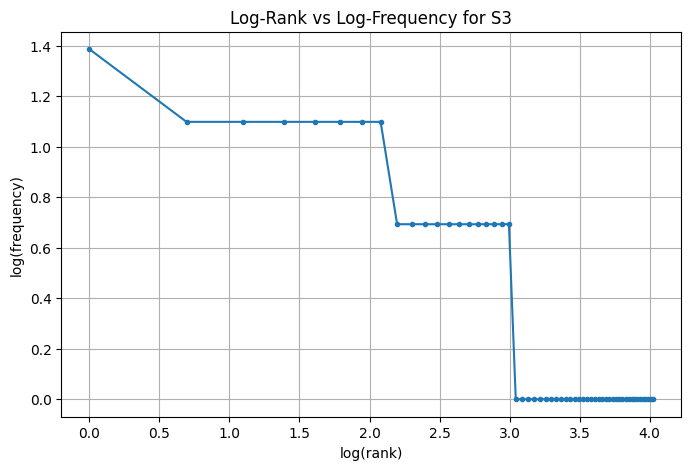


Top 5 bigrams of S1:
[(('the', 'laptop'), 3), (('after', 'the'), 3), (('the', 'latest'), 3), (('latest', 'update'), 3), (('update', '.'), 3)]

Top 5 bigrams of S3:
[(('latest', 'update'), 3), (('keeps', 'asking'), 2), (('asking', 'login'), 2), (('another', 'solution'), 2), (('keeps', 'disconnecting'), 2)]


In [11]:
# Your code

from collections import Counter
from nltk.util import ngrams
import matplotlib.pyplot as plt
import math
import pandas as pd

S1 = [token for result in processed for token in result["tokens"]]

S2 = [
    token
    for result in processed
    for token in result["tokens"]
    if not is_punct(token)
]

S3 = [token for result in processed for token in result["final"]]

S4 = [porter.stem(token) for token in S3]

corpora = {
    "S1": S1,
    "S2": S2,
    "S3": S3,
    "S4": S4
}

stats = []

for name, corpus in corpora.items():
    total = len(corpus)
    unique = len(set(corpus))
    ttr = unique / total if total else 0

    stats.append({
        "Corpus": name,
        "Total tokens": total,
        "Unique tokens": unique,
        "TTR": round(ttr, 4)
    })

display(pd.DataFrame(stats))

print("Top 10 words of S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words of S3:")
print(Counter(S3).most_common(10))

frequencies = sorted(Counter(S3).values(), reverse=True)
ranks = range(1, len(frequencies) + 1)

plt.figure(figsize=(8, 5))
plt.plot(
    [math.log(rank) for rank in ranks],
    [math.log(freq) for freq in frequencies],
    marker="."
)
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Log-Rank vs Log-Frequency for S3")
plt.grid(True)
plt.show()

def get_bigrams(token_key):
    counts = Counter()
    for result in processed:
        counts.update(ngrams(result[token_key], 2))
    return counts

print("\nTop 5 bigrams of S1:")
print(get_bigrams("tokens").most_common(5))

print("\nTop 5 bigrams of S3:")
print(get_bigrams("final").most_common(5))


Q6 Interpretation

(a) Why does TTR change from S1 to S4 in your dataset?

TTR changes because punctuation and stopwords are removed during preprocessing, and Porter stemming combines related word forms into common stems. This changes the total number of tokens and unique tokens, affecting vocabulary diversity.

(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.

For the contraction It's, my custom tokenizer preserves it as one token, while word_tokenize() splits it into It and 's. This happens because my regular expression is designed to preserve contractions.

(c) Give one example where stemming produces an undesirable result.

In my stemming table, Lancaster Stemmer reduces error to er. This is undesirable because it removes too much of the original word and produces an incomplete form.

(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.

For the adjective better, POS-aware WordNet lemmatization can return good, its dictionary base form. A stemmer may not identify this relationship because it primarily removes suffixes rather than considering grammatical meaning.